# Paper 12 — From Proposed Capabilities to a Verified Local Video

## Abstract

Paper 11 identifies candidate capabilities and gaps; its graph is not an executable assembly. This study implements one explicit still-image alternative as a two-scene illustrated research-video pipeline: a local model writes a constrained scene specification, a diagram renderer produces original visual frames, a pinned neural voice model generates narration, measured audio durations define scene captions, and a local encoder assembles the output. We preserve the first failed run and test a corrected run plus a changed brief. Independent artifact checks inspect decoding, signal, scene fidelity and caption boundaries. This is a bounded diagram-video prototype, **not diffusion-image generation, generated motion footage, automatic Langflow graph execution or a commercially cleared business pipeline**.

Use the video players below to inspect the actual outputs. To make another example, edit the brief in Section 5 and run its cell; the code creates a new isolated run rather than replacing earlier evidence.


## Audio-first workbench

[Open the programmable Money voice workbench](http://127.0.0.1:5194/).

The next development focus is voice quality. Select a node to edit narration, reference voice, generation, mastering or optional enhancement settings. Run the graph, then compare original and processed recordings at matched loudness. Save/load graph JSON to retain settings. This separate React Flow adapter reuses Money’s existing engines; it is not native Langflow registration. The original video study below remains unchanged.

## 1. Question, hypothesis and ways to be wrong

**Question:** Can we turn one Paper 11 capability proposal into a repeatable local illustrated-video implementation, while distinguishing real reuse from new code and preserving evidence for failures?

| Claim | Evidence required | Refutation |
|---|---|---|
| The proposed capabilities can be concretely realized in this visual mode | Actual scene JSON, images, generated speech, captions and MP4 | A capability remains a placeholder or needs an undeclared remote service |
| The pieces exchange compatible artifacts | Validated JSON, image size, PCM audio, measured timeline and encoded streams | Contract mismatch, invalid model output, silent audio or failed decoding |
| The output is repeatable beyond one fixed script | Changed input triggers a second real run | Only a canned asset or prewritten final video is returned |
| Evidence distinguishes implementation from references | Source/model hashes, origin table and run events | An archived Langflow reference is falsely counted as executed reuse |

**Alternatives:** A whole prebuilt template might be easier if it fits; system speech could reduce setup and license issues; a dedicated diffusion/motion model would support richer visuals but is not tested here. No method comparison or general superiority is claimed.


## 2. Design inherited from Paper 11

The selected branch is **image generation → still-image video assembly**, with narration and scene captions. Here the image capability is deliberately realized as **original generated diagram illustrations**: the local model generates labels and structure, then deterministic drawing code rasterizes them. This supports instructional diagrams only. It cannot substitute for a request requiring photos, arbitrary visual scenes or generative motion.

| Capability | Paper 11 evidence | Actual implementation in this paper |
|---|---|---|
| Script input | Archived Text Input reference | New brief validator plus local scene planner; archived code is not run |
| Images | No admissible complete local candidate selected | New bounded diagram renderer driven by local model output |
| Narration | Archived OpenAI-named candidate remains unverified | Reuse the existing pinned local F5 runtime via an isolated adapter; not the archived candidate |
| Captions | Retrieved AssemblyAI choices conflict with local-only | New measured scene-level SRT and visible caption renderer |
| Assembly | No qualifying retrieved match | Existing local FFmpeg binary plus new encoding/concat orchestration |

The outcome tests manual implementation of a proposed contract, **not automatic template composition**. The frozen proposal is retained in `INPUT-PROPOSAL.json`; `INSTANCE.json` maps process, flow, composites, components and configuration.


In [1]:
import sys,json,uuid,hashlib,subprocess
from pathlib import Path
from IPython.display import display,Video,Image,Markdown,JSON
import pandas as pd
root=Path('/Users/x/projects/swarms')
study=root/'knowledge/research/paper-12-study'
sys.path.insert(0,str(study))
from pipeline import build,digest
from verify_run import verify
instance=json.loads((study/'INSTANCE.json').read_text())
display(pd.DataFrame(instance['components']))
display(JSON(instance,expanded=False))


,capability,implementation,provenance
0,script_input,brief validator and local scene planner,new adapter; archived Text Input is a design r...
1,image_generation,Pillow diagram renderer driven by local Ollama...,new bounded visual implementation; not diffusi...
2,narration,pinned local F5-TTS model on MPS via existing ...,actual code/model reuse from the local Money p...
3,subtitles,new scene-level captions from measured audio d...,new adapter; AssemblyAI candidates are not use...
4,video_assembly,local FFmpeg H.264/AAC scene encoding and concat,existing binary reused; new orchestration adapter


<IPython.core.display.JSON object>

## 3. Contracts and configuration

| Record/artifact | Contract | Check |
|---|---|---|
| Brief | 10–1000 characters | Reject before model request |
| Scene plan | Exactly two scenes; short headline, 5–28-word narration, three short diagram labels | Explicit field and length validation; generated code is never executed |
| Image | 1280×720 RGB PNG with generated diagram and visible scene narration | Image decode, dimensions and overflow checks |
| Narration | Local neural synthesis; mono PCM16 WAV; duration 1–60 seconds | Non-finite/silence checks and observed MPS model calls |
| Captions | Scene text, boundaries derived from measured WAV duration | Exact regenerated-SRT comparison; no word-level alignment claim |
| Video | 24 fps H.264/AAC MP4 with both scenes | Full independent audio/video decode and sampled-frame fidelity |
| Run | Unique folder, ordered real stage events, hashes, failure or success | Existing folders never overwritten; failures retained |

The environment reuses installed local tools and pinned weights; no new models were downloaded. Paths currently bind this implementation to this host. Operating-system isolation and portable installation are not established. Neural inference can use upstream CPU fallbacks even when model dispatch is on MPS; memory categories reported by upstream instrumentation overlap and must not be summed.


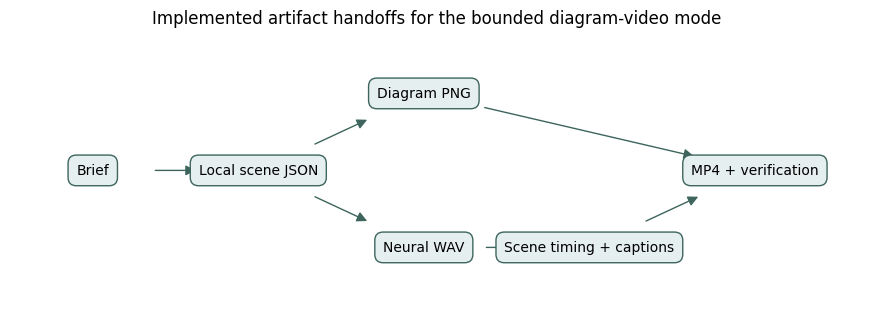

In [2]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyArrowPatch
fig,ax=plt.subplots(figsize=(11,3.6))
positions={'Brief':(0,1),'Local scene JSON':(2,1),'Diagram PNG':(4,2),'Neural WAV':(4,0),'Scene timing + captions':(6,0),'MP4 + verification':(8,1)}
for label,(x,y) in positions.items():
    ax.text(x,y,label,ha='center',va='center',fontsize=10,bbox=dict(boxstyle='round,pad=.6',facecolor='#e6eff0',edgecolor='#3d655d'))
for a,b in [('Brief','Local scene JSON'),('Local scene JSON','Diagram PNG'),('Local scene JSON','Neural WAV'),('Neural WAV','Scene timing + captions'),('Diagram PNG','MP4 + verification'),('Scene timing + captions','MP4 + verification')]:
    ax.add_patch(FancyArrowPatch(positions[a],positions[b],arrowstyle='-|>',shrinkA=45,shrinkB=45,mutation_scale=15,color='#3d655d'))
ax.set(xlim=(-1,9.3),ylim=(-.8,2.8),title='Implemented artifact handoffs for the bounded diagram-video mode');ax.axis('off');plt.show();plt.close(fig)


## 4. Implementation and observed failure

The executable implementation lives in the adjacent study: `pipeline.py` coordinates the validated interfaces, `tts_worker.py` wraps existing pinned voice code in an isolated output location, and `verify_run.py` separately checks the resulting artifacts.

The first real attempt produced an image and speech but failed when the reused voice wrapper tried to read model lock metadata from its new isolated root. The repair copies the lock metadata into that root before inference. It does not change the other project's saved configuration or latest-output pointer. The failed run remains saved and is not counted as successful. A subsequent notebook-run attempt exposed an inherited Matplotlib inline-backend setting that the voice environment did not support. The worker now sets its own noninteractive backend before importing inference code. That failed attempt also remains saved. Corrected runs are independently inspected below.


In [3]:
failed=json.loads((study/'.runtime/first-proof/run.json').read_text())
first_folder=study/'.runtime/first-proof-fixed'
first=json.loads((first_folder/'run.json').read_text())
first_check=verify(first_folder)
display(pd.DataFrame([{'Attempt':'Original','Status':failed['status'],'Observed result':failed.get('error','')[-350:]},{'Attempt':'Corrected','Status':first['status'],'Observed result':f"{first['duration_seconds']} second MP4; independent decode passed"}]))
display(Video(first['final'],embed=True,width=800))


,Attempt,Status,Observed result
0,Original,failed,"e/lib/python3.12/pathlib.py"", line 1013, in op..."
1,Corrected,passed,13.13 second MP4; independent decode passed


## 5. Changed-input experiment — real execution

This cell runs the full pipeline on a second brief. It is not a replay of the first video. Generation may take a few minutes; a model or contract failure stops the cell and retains the failure evidence. The visual mode and two-scene bounds remain fixed. Editing `brief` and re-running creates another uniquely named experiment.


In [4]:
brief='Explain why a proposed connection needs testing. Scene one should distinguish a declared input and output from a working handoff. Scene two should show a small test, a failure report and a revised design.'
second=build(brief,run_name='notebook-change-'+uuid.uuid4().hex[:10])
second_folder=Path(second['final']).parent
second_check=verify(second_folder)
assert second['output_sha256']!=first['output_sha256'], 'Changed input must not return the same final asset'
display(Video(second['final'],embed=True,width=800))
display(JSON(second_check,expanded=False))


<IPython.core.display.JSON object>

## 6. Contract and corruption tests

Controlled tests reject malformed plans, excess text, unexpected generated code fields, invalid caption durations and unsafe run names. They also validate actual rendered images and exact scene-caption timing. These tests exercise implementation contracts; the two real model runs provide runtime evidence separately.

The corruption checks below operate on copies. A changed video hash must fail, and a mismatched caption must fail even when the video itself remains decodable.


In [5]:
tests=subprocess.run([sys.executable,'-B',str(study/'test_pipeline.py')],capture_output=True,text=True)
print(tests.stdout+tests.stderr)
assert tests.returncode==0
import shutil,tempfile
negative=[]
for defect in ['video_tamper','caption_tamper']:
    with tempfile.TemporaryDirectory() as td:
        target=Path(td)/'run';shutil.copytree(first_folder,target)
        for report_path in target.glob('tts-*.json'):
            r=json.loads(report_path.read_text());r['audio']=str(target/Path(r['audio']).relative_to(first_folder));report_path.write_text(json.dumps(r))
        if defect=='video_tamper':
            video=target/'final.mp4';video.write_bytes(video.read_bytes()[:-512])
        else:(target/'captions.srt').write_text('Incorrect captions')
        try:verify(target)
        except ValueError as exc:negative.append({'Defect':defect,'Rejected':True,'Reason':str(exc)})
        else:raise AssertionError('Corrupted artifact was accepted')
display(pd.DataFrame(negative))


test_audio_timeline_caption_boundaries (__main__.Contracts.test_audio_timeline_caption_boundaries) ... ok
test_invalid_timing_fails (__main__.Contracts.test_invalid_timing_fails) ... ok
test_real_image_contract (__main__.Contracts.test_real_image_contract) ... ok
test_rejects_code_as_scene (__main__.Contracts.test_rejects_code_as_scene) ... ok
test_rejects_missing_scene (__main__.Contracts.test_rejects_missing_scene) ... ok
test_rejects_overlong_narration (__main__.Contracts.test_rejects_overlong_narration) ... ok
test_text_never_shell_executes (__main__.Contracts.test_text_never_shell_executes) ... ok
test_unsafe_run_name_fails (__main__.Contracts.test_unsafe_run_name_fails) ... ok
test_valid_plan (__main__.Contracts.test_valid_plan) ... ok

----------------------------------------------------------------------
Ran 9 tests in 0.029s

OK



,Defect,Rejected,Reason
0,video_tamper,True,Final hash mismatch
1,caption_tamper,True,Caption text/timing differs from measured scen...


## 7. Results and actual execution trace

The table and timeline are computed from saved runtime events and independent checks. Durations describe these exposed development runs only; two examples do not establish a performance distribution, reliability rate or generalization. Matching decoded frames supports preservation of the illustrations and visible captions; it does not prove instructional usefulness or speech intelligibility.


,Run,Video seconds,Runtime seconds,Full independent decode,Caption boundaries match audio,Minimum frame PSNR dB,Observed neural forward calls
0,Corrected request,13.13,22.926,True,True,40.520520,32
1,Changed brief,17.13,23.762,True,True,40.229149,32


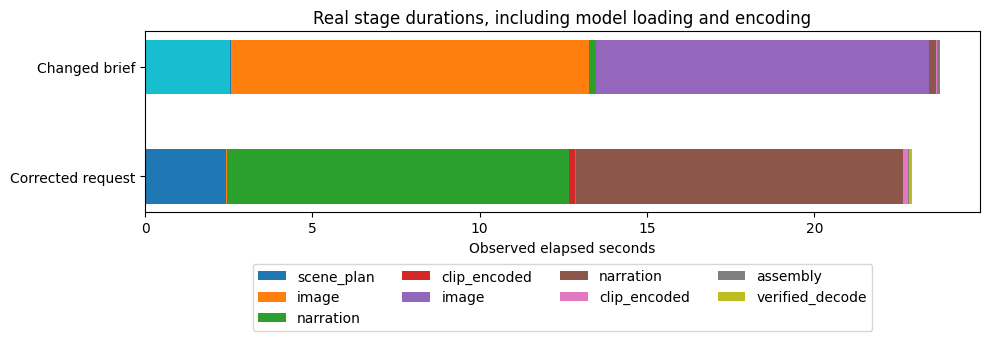

Two different briefs produced different locally generated outputs; no claim of general system generation.


In [6]:
results=[]
for label,record,check in [('Corrected request',first,first_check),('Changed brief',second,second_check)]:
    results.append({'Run':label,'Video seconds':record['duration_seconds'],'Runtime seconds':record['events'][-1]['elapsed_seconds'],'Full independent decode':check['independent_full_decode'],'Caption boundaries match audio':check['captions_match_generated_text_and_audio_boundaries'],'Minimum frame PSNR dB':min(check['decoded_scene_psnr_db']),'Observed neural forward calls':sum(check['observed_transformer_calls'])})
display(pd.DataFrame(results))
fig,ax=plt.subplots(figsize=(10,3.8))
for row,(label,record) in enumerate([('Corrected request',first),('Changed brief',second)]):
    previous=0
    for event in record['events'][1:]:
        elapsed=event['elapsed_seconds'];ax.barh(row,elapsed-previous,left=previous,label=event['stage'] if row==0 else None,height=.5);previous=elapsed
ax.set_yticks([0,1],['Corrected request','Changed brief']);ax.set_xlabel('Observed elapsed seconds');ax.set_title('Real stage durations, including model loading and encoding');ax.legend(loc='upper center',bbox_to_anchor=(.5,-.25),ncol=4);plt.tight_layout();plt.show();plt.close(fig)
evidence={'runs':[{'folder':str(first_folder),'result':first,'independent':first_check},{'folder':str(second_folder),'result':second,'independent':second_check}],'negative_checks':negative,'contract_tests_returncode':tests.returncode,'scope':instance['hard_limits']}
(study/'EVIDENCE.json').write_text(json.dumps(evidence,indent=2)+'\n')
print('Two different briefs produced different locally generated outputs; no claim of general system generation.')


## 8. Defense, limitations and what we learned

1. A proposed capability box needs an explicit implementation decision. An archived reference is not proof that its code was reused, instantiated or executed.
2. Artifact contracts exposed a real integration failure. Model inference alone was insufficient: output metadata and storage boundaries also had to work.
3. Measured narration duration can support scene-level video/caption assembly without a remote transcription service. This does not supply word-level forced alignment.
4. A valid small diagram-video pipeline does not solve arbitrary image or motion generation. Those require different implementations and new runtime evidence.
5. The first successful examples remain exposed development cases. Human review of speech, visual comprehension and instructional quality is still required before claiming product usefulness.

**Commercial boundary:** F5's pretrained weights are listed under a noncommercial license. This research demonstration is not a voice stack cleared for monetized publishing. A production business needs a commercially suitable voice/model and reference-rights review. The code license and model-weight license must be assessed separately. See the [official repository](https://github.com/SWivid/F5-TTS) and [model card](https://huggingface.co/SWivid/F5-TTS).

**What remains outside this paper's result:** general image/motion generation, automatic Langflow composition, arbitrary user requests, photorealism, cost optimization, audience response, profitability, portable deployment and operating-system-level network isolation.


## 9. Reproducibility, sources and conclusion

The notebook contains runnable orchestration cells and embedded generated outputs. The study folder retains the input proposal, selected instance definition, brief, code, failed and successful run logs, independent verification and source references. Large pre-existing model assets stay in their existing external runtime. Runtime folders are separate from source code and are not overwritten by re-running.

Primary implementation references:
- [Ollama Generate API](https://docs.ollama.com/api/generate): local inference and structured JSON output.
- [F5-TTS official implementation](https://github.com/SWivid/F5-TTS): neural speech code; model asset revisions are recorded by inference.
- [F5-TTS model card](https://huggingface.co/SWivid/F5-TTS): pretrained-model licensing boundary.
- [FFmpeg FAQ](https://www.ffmpeg.org/faq.html): concatenation of compatible media streams.

**Conclusion:** the artifact and runtime results above establish a bounded path from a proposed capability contract to local illustrated-video execution. They establish neither automatic template assembly nor general video generation. The next extension should replace one bounded implementation at a time and repeat artifact, runtime and human-quality checks rather than relabeling the existing result as a broader success.


## 10. Audio-first integration and measured evidence

Money’s existing F5 generation, mastering, and Resemble Enhance engines are now exposed as four configurable React Flow nodes: narration → voice → master → optional enhancement. The backend validates typed connections and settings before execution. It emits real stage events, isolates each run, preserves originals, and allows cancellation of its own worker. Enhancement can be removed from the graph. Graph JSON can be saved and validated on load; prepared reference audio can be previewed.

| Check | Observed result |
|---|---|
| Full engine chain | Two new runs completed all three processing stages |
| Generated speech | 14.624 s, 24 kHz |
| Mastered speech | 14.624 s, 48 kHz; independently measured −16.0 LUFS, −1.5 dBTP |
| Enhanced speech | 14.624 s, 44.1 kHz; actual neural forward calls recorded |
| Matched listening pairs | Both measured 0.0 LU difference |
| Artifact lineage | Generated file feeds mastering; master feeds enhancement; source copies hash-match |
| Contract and HTTP tests | 15 passed, including invalid graphs, isolation, reference playback and cancellation |
| Browser checks | Real playback, exclusive playback, saved graph reload, optional-stage wiring and result restoration |
| Preservation | Money settings and latest-output pointers match pre-integration hashes |

Evidence: `services/audio-workbench/.runtime/f0f53720ed922ee3d78a2909` and `services/audio-workbench/.runtime/0f4a9c67934ef163d638cf99`. Each retains request, events, reports and audio; the latest also retains the executed worker snapshot and independent verification. Recheck with `verify_audio.py` as described in the service README.

**Limits.** These tests establish processing and artifact integrity, not subjective superiority, pronunciation accuracy or commercial clearance. Listen before choosing an output. The adapter supports a bounded four-node chain, prepared references rather than custom uploads, and serial local inference. Sessions are held in memory; audio files remain on disk after restart. F5 pretrained weights and research references are not cleared here for monetized publishing. Video expansion is deferred.

## 11. Full Money audio controls

The workbench now covers active and original references, custom-reference upload and transcript, all integer sampling steps 8–64, independent speech/mastering/enhancement actions, uploaded recordings for mastering, matched versus actual-volume playback, saved session defaults and graph JSON export/import.

Advanced controls expose the existing engine configuration: generation crossfade, guidance and sway; mastering sample rate, loudness/peak/range targets, EQ, compression and de-essing; enhancement solver, temperature, seed, threads and maximum duration. The installed checkpoint/device remain pinned. Per-run configuration overrides do not modify Money's configuration.

| Check | Observed evidence |
|---|---|
| Non-default full chain | Custom reference, 17 steps, −18 LUFS / 44.1 kHz master, Euler enhancement completed |
| Independent meter | Full-chain master measured −18.0 LUFS; both matched pairs differed by 0.0 LU |
| Uploaded recording | Master and enhancement completed without speech generation |
| Enhancement only | Existing master processed without rerunning earlier stages |
| Automated checks | 20 passed, including settings bounds, invalid uploads, session isolation and cancellation |
| Browser | Original reference selection; speech-only, mastering-only and enhancement-only execution; custom upload/transcript; defaults restore; graph export/load |
| Preservation | Money configuration and latest-output pointer hashes unchanged |

Source-to-control audit: `services/audio-workbench/CONTROLS.md`. Run evidence: `services/audio-workbench/full-controls-verification.json`. Session upload tokens require re-upload after session/server loss; graph JSON exports settings. Technical checks do not establish subjective superiority or commercial rights. Video expansion remains deferred.